## A loop of your own

An `Engine` is an account at a venue for a loop the caller owns, stepped one bar at a time,
with the verbs and state a Strategy's account has. Here two of them, at Binance and Bybit,
step together over 2025's hourly bars of Bitcoin's perpetual: short where the last funding
rate is higher, long where it is lower, so the two legs offset in price and the account
collects the difference. `combine` then adds the two accounts into one book.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import matplotlib.ticker
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 2.0.0, exchange-router 3.0.1


### The bars at both venues

Each venue's hourly perpetual with its funding, fetched once into `bars/` and cut to 2025.

In [2]:
BINANCE = pathlib.Path("../bars/binance-linear-btcusdt-ethusdt-1h-2024-2025")
BYBIT   = pathlib.Path("../bars/bybit-linear-btcusdt-1h-2025")

if BINANCE.exists():
    perp = probatum.Data.load(path=BINANCE)
else:
    with exchange_router.Router.local(exchanges=["binance"]) as router:
        perp = probatum.Data.from_router(router, exchange="binance", market="linear",
                                         interval="1h", symbols=["BTCUSDT", "ETHUSDT"],
                                         start="2024-01-01", end="2025-12-31", funding=True)
    perp.save(path=BINANCE)

if BYBIT.exists():
    bybit = probatum.Data.load(path=BYBIT)
else:
    with exchange_router.Router.local(exchanges=["bybit"]) as router:
        bybit = probatum.Data.from_router(router, exchange="bybit", market="linear",
                                          interval="1h", symbols=["BTCUSDT"],
                                          start="2025-01-01", end="2025-12-31", funding=True)
    bybit.save(path=BYBIT)

binance = perp["BTCUSDT"].after(when="2025-01-01")

print(binance, binance.provenance["venue"])
print(bybit, bybit.provenance["venue"])
print(f"one clock: {numpy.array_equal(binance.time, bybit.time)}")

Data(BTCUSDT, 1h, 8760 bars from 2025-01-01 00:00 to 2025-12-31 23:00) binance
Data(BTCUSDT, 1h, 8760 bars from 2025-01-01 00:00 to 2025-12-31 23:00) bybit
one clock: True


### The loop

Each step fills on the next bar what was decided at the last close, and returns that bar.
A side is taken only where the two rates are more than half a basis point apart, and kept
until they cross that far the other way.

In [3]:
at_binance = probatum.Engine(binance, venue="binance_perp")
at_bybit   = probatum.Engine(bybit, venue="bybit_perp")

left, right = at_binance.reset(), at_bybit.reset()
side, turns = 0.0, 0

while not at_binance.done():
    gap    = left.funding_rate - right.funding_rate
    wanted = -1.0 if gap > 0.00005 else 1.0 if gap < -0.00005 else side

    if wanted != side:
        at_binance.target(weights=0.5 * wanted)
        at_bybit.target(weights=-0.5 * wanted)
        side, turns = wanted, turns + 1

    left, right = at_binance.step(), at_bybit.step()

print(f"{turns} turns over {len(binance):,} bars")

82 turns over 8,760 bars


### One book of two accounts

Each account is margined on its own, and no capital moves between them; the book's equity is
their sum, its statistics those of the sum.

In [4]:
book = probatum.combine({"binance": at_binance.result(), "bybit": at_bybit.result()})

book

,run,buy_and_hold,low,high,level,method,why_none
total_return_pct,-3.86,-12.80,-8.94,1.50,0.95,"studentized stationary block bootstrap, blocks of 81.4 bars",
cagr_pct,-3.86,-12.80,-8.94,1.50,0.95,"studentized stationary block bootstrap, blocks of 81.4 bars",
volatility_pct,3.15,45.19,2.83,3.50,0.95,"studentized stationary block bootstrap, blocks of 81.4 bars",
sharpe,-1.23,-0.08,-3.19,0.72,0.95,"delta method, Newey-West lag 22, floored at lag zero",
max_drawdown_pct,5.22,36.27,2.22,9.67,0.95,"middle of resampled histories, stationary block bootstrap, blocks of 81.4 bars",
exposure_pct,98.28,,,,,,
num_trades,162,,,,,,
win_rate,0.47,,0.40,0.54,0.95,percentile bootstrap of round trips,
profit_factor,0.93,,0.61,1.45,0.95,BCa bootstrap of round trips,
costs,920,,,,,,


### What each account kept and paid

Each account's closing equity and the totals of its costs, funding among them, a negative
sum being funding received.

In [5]:
accounts = {"binance": at_binance.result(), "bybit": at_bybit.result()}

pandas.DataFrame({name: {"equity, USDT": run.equity[-1], **run.costs}
                  for name, run in accounts.items()}).T.round(decimals=2)

,"equity, USDT",fees,funding,spread,slippage,impact,liquidation,dust
binance,7598.0,340.05,-11.68,9.23,66.94,0.72,0.0,0.0
bybit,11629.9,497.88,-72.00,0.00,87.08,1.51,0.0,0.0


### The two accounts and the book

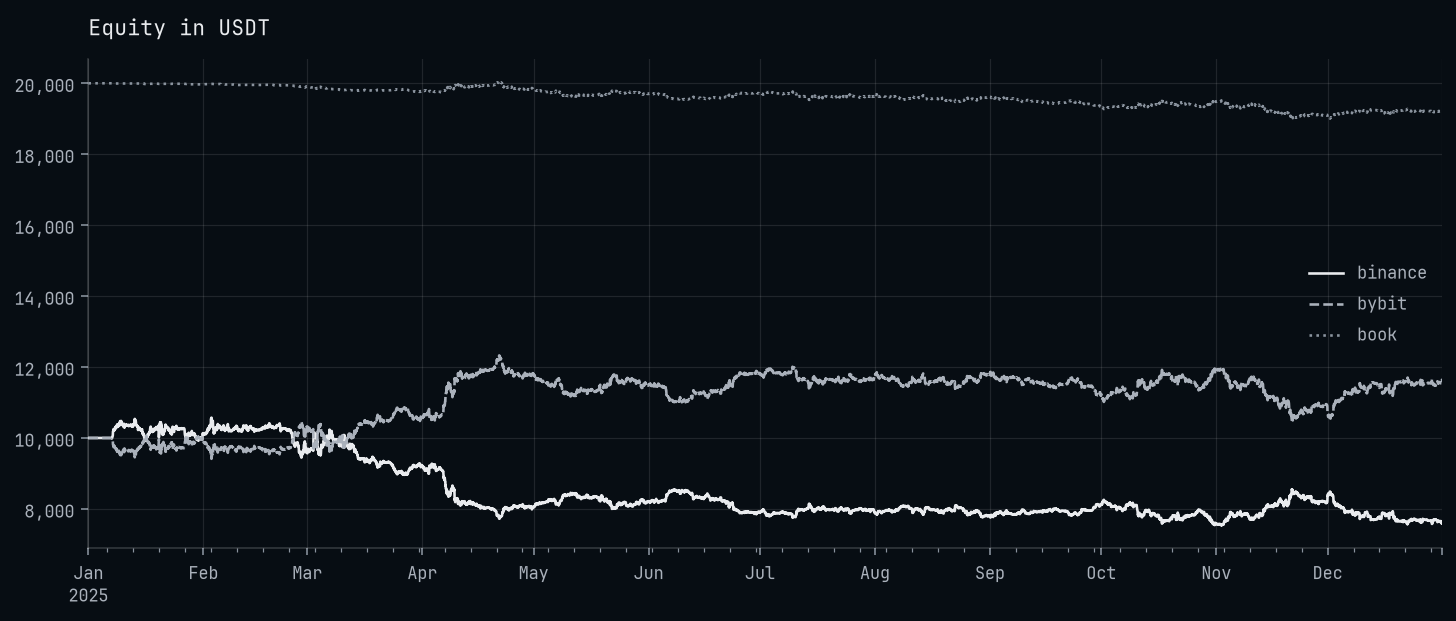

In [6]:
equity = pandas.DataFrame({name: run.equity for name, run in accounts.items()},
                          index=pandas.to_datetime(binance.time, utc=True))
equity["book"] = book.equity[-len(equity):]

axes = equity.plot(title="Equity in USDT", xlabel="")
axes.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter(fmt="{x:,.0f}"))
matplotlib.pyplot.show()